In [1]:
# Konfiguracja wyglądu punktów i linii dopasowania
POINT_STYLES = {
    "morning": {
        "stations": {"color": "#80C4E9", "size": 30, "alpha": 0.40, "linewidth": 0},
        "binned": {"color": "#102A43", "size": 70, "alpha": 0.7, "marker": "D"},
        "excluded": {"facecolor": "white", "edgecolor": "#102A43", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
        "fit": "#8054A3",
        "marker": "o",
    },
    "midday": {
        "stations": {"color": "#8FD6AC", "size": 30, "alpha": 0.40, "linewidth": 0},
        "binned": {"color": "#216B50", "size": 70, "alpha": 0.7, "marker": "D"},
        "excluded": {"facecolor": "white", "edgecolor": "#216B50", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
        "fit": "#D18A36",
        "marker": "s",
    },
    "afternoon_peak": {
    "stations": {"color": "#F4B29B", "size": 30, "alpha": 0.40, "linewidth": 0},
    "binned": {"color": "#A64B36", "size": 70, "alpha": 0.7, "marker": "D"},
    "excluded": {"facecolor": "white", "edgecolor": "#A64B36", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
    "fit": "#864E91",
    "marker": "^",
    },
    "evening": {
        "stations": {"color": "#C4B3E8", "size": 30, "alpha": 0.40, "linewidth": 0},
        "binned": {"color": "#59417D", "size": 70, "alpha": 0.7, "marker": "D"},
        "excluded": {"facecolor": "white", "edgecolor": "#59417D", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
        "fit": "#D28B45",
        "marker": "s",
    },
}

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "log_binning_aw.py").is_file():
        if str(path) not in sys.path:
            sys.path.insert(0, str(path))
        break
else:
    raise FileNotFoundError("Could not find log_binning_aw.py")

from log_binning_aw import log_binning_aw

def _apply_project_plot_style():
    current = Path.cwd()
    for path in [current, *current.parents]:
        if (path / "plot_style.py").is_file():
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))

            import plot_style

            plot_style.apply_montserrat_style()
            return

_apply_project_plot_style()

In [2]:
def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start)
    for path in [current, *current.parents]:
        if (path / "Data").exists():
            return path
    raise FileNotFoundError("Could not find project root containing Data/")


PROJECT_ROOT = find_project_root()
BASE_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "Data"
DATA_FILE = DATA_DIR / "rides_data_without_discontinuities.parquet"

rides_data = pd.read_parquet(DATA_FILE, columns=[
    "start_station_id", "start_station_name", "start_date", "start_day_of_week"
])

### Wykluczanie stacji, dla których nie było ciągłości działania

In [3]:
# Stacje wykluczone z analizy
excluded_stations = {22181, 200032, 300060, 300074, 300099}

# Filtrowanie danych
rides_data_filtered = rides_data[
    ~pd.to_numeric(
        rides_data["start_station_id"], errors="coerce"
    ).isin(excluded_stations)
].copy()

# Podsumowanie
print(f"Liczba stacji przed filtrowaniem: {rides_data['start_station_id'].nunique()}")
print(f"Liczba stacji po filtrowaniu: {rides_data_filtered['start_station_id'].nunique()}")

Liczba stacji przed filtrowaniem: 801
Liczba stacji po filtrowaniu: 796


In [4]:
# Podział danych na 4 okresy dla dni roboczych:
# 6:00 - 8:59   -> poranny szczyt
# 10:00 - 12:59 -> okres poza szczytem
# 15:00 - 17:59 -> popołudniowy szczyt
# 19:00 - 21:59 -> okres wieczorny

rides_data_weekdays = rides_data_filtered[rides_data_filtered["start_day_of_week"].isin(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])].copy()

rides_data_weekdays.head(5)

,start_station_id,start_station_name,start_date,start_day_of_week
0,200254,"Teviot Street, Poplar",2024-01-11 07:48:00,Thursday
1,300048,"Stainsby Road , Poplar",2024-01-11 08:25:00,Thursday
2,300208,"Lavington Street, Bankside",2024-01-11 15:07:00,Thursday
3,200105,"Bonny Street, Camden Town",2024-01-12 10:42:00,Friday
5,1091,"St. John's Wood Church, The Regent's Park",2024-01-15 13:35:00,Monday


In [5]:
# Poranny szczyt: 6:00 - 8:59
rides_data_morning_peak = rides_data_weekdays[
    rides_data_weekdays["start_date"].dt.hour.between(6, 8)
].copy()

# Okres poza szczytem: 10:00 - 12:59
rides_data_midday = rides_data_weekdays[
    rides_data_weekdays["start_date"].dt.hour.between(10, 12)
].copy()

# Popołudniowy szczyt: 15:00 - 17:59
rides_data_afternoon_peak = rides_data_weekdays[
    rides_data_weekdays["start_date"].dt.hour.between(15, 17)
].copy()

# Okres wieczorny: 19:00 - 21:59
rides_data_evening = rides_data_weekdays[
    rides_data_weekdays["start_date"].dt.hour.between(19, 21)
].copy()

In [6]:
# Zamiana kolumny "start_date" na typ daty bez czasu
rides_data_morning_peak["start_date"] = rides_data_morning_peak["start_date"].dt.date.copy()
rides_data_midday["start_date"] = rides_data_midday["start_date"].dt.date.copy()
rides_data_afternoon_peak["start_date"] = rides_data_afternoon_peak["start_date"].dt.date.copy()
rides_data_evening["start_date"] = rides_data_evening["start_date"].dt.date.copy()

In [7]:
# Policzenie ile było przejazdów dla każdej stacji dzień po dniu
morning_peak_rides_per_station = (
    rides_data_morning_peak
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

midday_rides_per_station = (
    rides_data_midday
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

afternoon_peak_rides_per_station = (
    rides_data_afternoon_peak
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

evening_rides_per_station = (
    rides_data_evening
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

In [8]:
# Wszystkie dni robocze w latach 2024–2025
days = pd.date_range("2024-01-01", "2025-12-31", freq="B").date

# Wszystkie analizowane stacje
station_ids = rides_data_filtered["start_station_id"].unique()

# Uzupełnienie brakujących dni i stacji zerami
morning_peak_rides_per_station = morning_peak_rides_per_station.reindex(
    index=station_ids, columns=days
).fillna(0)

midday_rides_per_station = midday_rides_per_station.reindex(
    index=station_ids, columns=days
).fillna(0)

afternoon_peak_rides_per_station = afternoon_peak_rides_per_station.reindex(
    index=station_ids, columns=days
).fillna(0)

evening_rides_per_station = evening_rides_per_station.reindex(
    index=station_ids, columns=days
).fillna(0)

In [9]:
# Średnia i wariancja dla każdej stacji

morning_peak_mean_and_variance_counts = pd.DataFrame({
    "mean_count": morning_peak_rides_per_station.mean(axis=1),
    "variance": morning_peak_rides_per_station.var(axis=1, ddof=0)
}).reset_index()

midday_mean_and_variance_counts = pd.DataFrame({
    "mean_count": midday_rides_per_station.mean(axis=1),
    "variance": midday_rides_per_station.var(axis=1, ddof=0)
}).reset_index()

afternoon_peak_mean_and_variance_counts = pd.DataFrame({
    "mean_count": afternoon_peak_rides_per_station.mean(axis=1),
    "variance": afternoon_peak_rides_per_station.var(axis=1, ddof=0)
}).reset_index()

evening_mean_and_variance_counts = pd.DataFrame({
    "mean_count": evening_rides_per_station.mean(axis=1),
    "variance": evening_rides_per_station.var(axis=1, ddof=0)
}).reset_index()

Pozbywanie się danych odstającyh - bardzo małych wartości

In [10]:
# Minimalne wartości średniej i wariancji
MIN_MEAN = 0.1
MIN_VARIANCE = 0.1

# Funkcja filtrująca
def filter_low_values(data):
    mask = (
        (data["mean_count"] >= MIN_MEAN) &
        (data["variance"] >= MIN_VARIANCE)
    )
    return data.loc[mask].copy()


# Filtrowanie danych
morning_peak_filtered = filter_low_values(morning_peak_mean_and_variance_counts)
midday_filtered = filter_low_values(midday_mean_and_variance_counts)
afternoon_peak_filtered = filter_low_values(afternoon_peak_mean_and_variance_counts)
evening_filtered = filter_low_values(evening_mean_and_variance_counts)

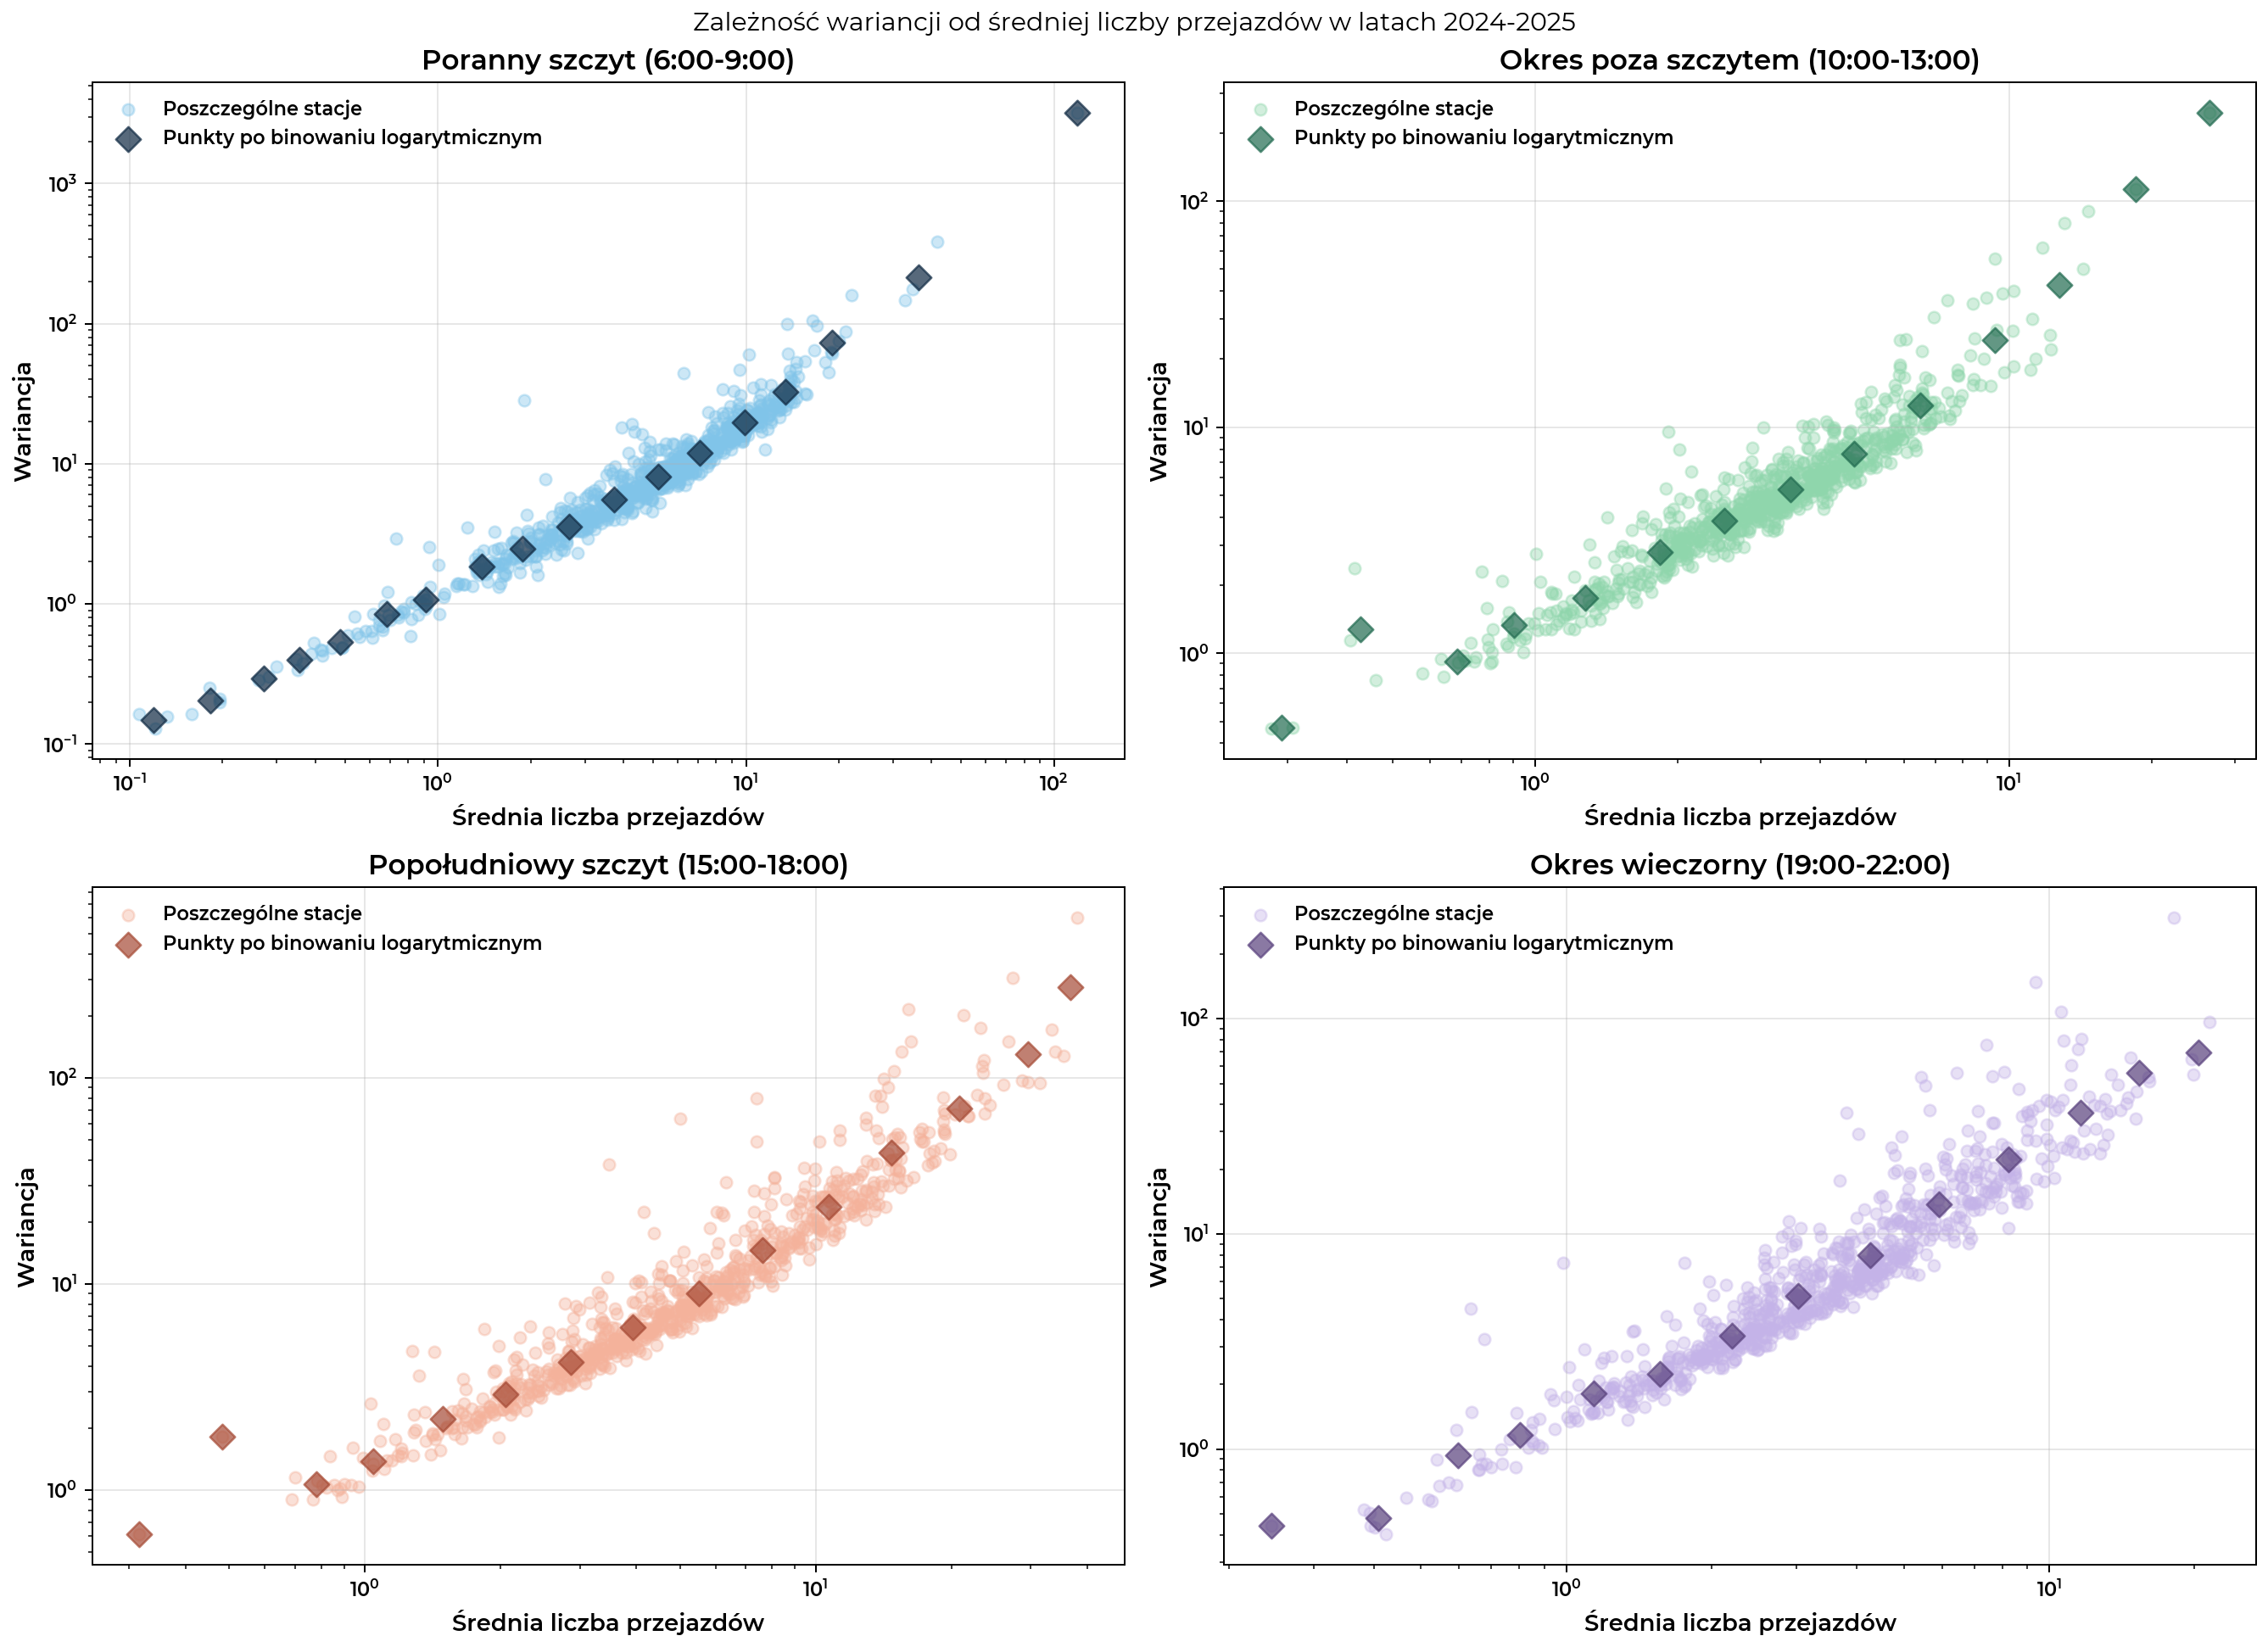

In [11]:
# Logarytmiczne przedziały
morning_peak_mean_log, morning_peak_variance_log = log_binning_aw(
    morning_peak_filtered["mean_count"],
    morning_peak_filtered["variance"],
    a=1.4
)

midday_mean_log, midday_variance_log = log_binning_aw(
    midday_filtered["mean_count"],
    midday_filtered["variance"],
    a=1.4
)

afternoon_peak_mean_log, afternoon_peak_variance_log = log_binning_aw(
    afternoon_peak_filtered["mean_count"],
    afternoon_peak_filtered["variance"],
    a=1.4
)

evening_mean_log, evening_variance_log = log_binning_aw(
    evening_filtered["mean_count"],
    evening_filtered["variance"],
    a=1.4
)

# Dane do wykresów
datasets = {
    "Poranny szczyt (6:00-9:00)": (
        morning_peak_filtered,
        morning_peak_mean_log,
        morning_peak_variance_log
    ),
    "Okres poza szczytem (10:00-13:00)": (
        midday_filtered,
        midday_mean_log,
        midday_variance_log
    ),
    "Popołudniowy szczyt (15:00-18:00)": (
        afternoon_peak_filtered,
        afternoon_peak_mean_log,
        afternoon_peak_variance_log
    ),
    "Okres wieczorny (19:00-22:00)": (
        evening_filtered,
        evening_mean_log,
        evening_variance_log
    )
}

# Wykres
_apply_project_plot_style()
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

# Kolorystyki dla kolejnych okresów dnia
style_keys = ["morning", "midday", "afternoon_peak", "evening"]

for ax, (period, (data, mean_log, variance_log)), style_key in zip(axes, datasets.items(), style_keys):

    styles = POINT_STYLES[style_key]

    # Chmura punktów
    ax.scatter(
        data["mean_count"],
        data["variance"],
        color=styles["stations"]["color"],
        alpha=styles["stations"]["alpha"],
        s=styles["stations"]["size"],
        zorder=1,
        label="Poszczególne stacje"
    )

    # Punkty po binowaniu logarytmicznym
    ax.scatter(
        mean_log,
        variance_log,
        color=styles["binned"]["color"],
        alpha=styles["binned"]["alpha"],
        marker="D",
        s=styles["binned"]["size"],
        zorder=3,
        label="Punkty po binowaniu logarytmicznym"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Średnia liczba przejazdów")
    ax.set_ylabel("Wariancja")
    ax.set_title(period)

    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

fig.suptitle(
    "Zależność wariancji od średniej liczby przejazdów w latach 2024-2025"
)

plt.tight_layout()
plt.show()

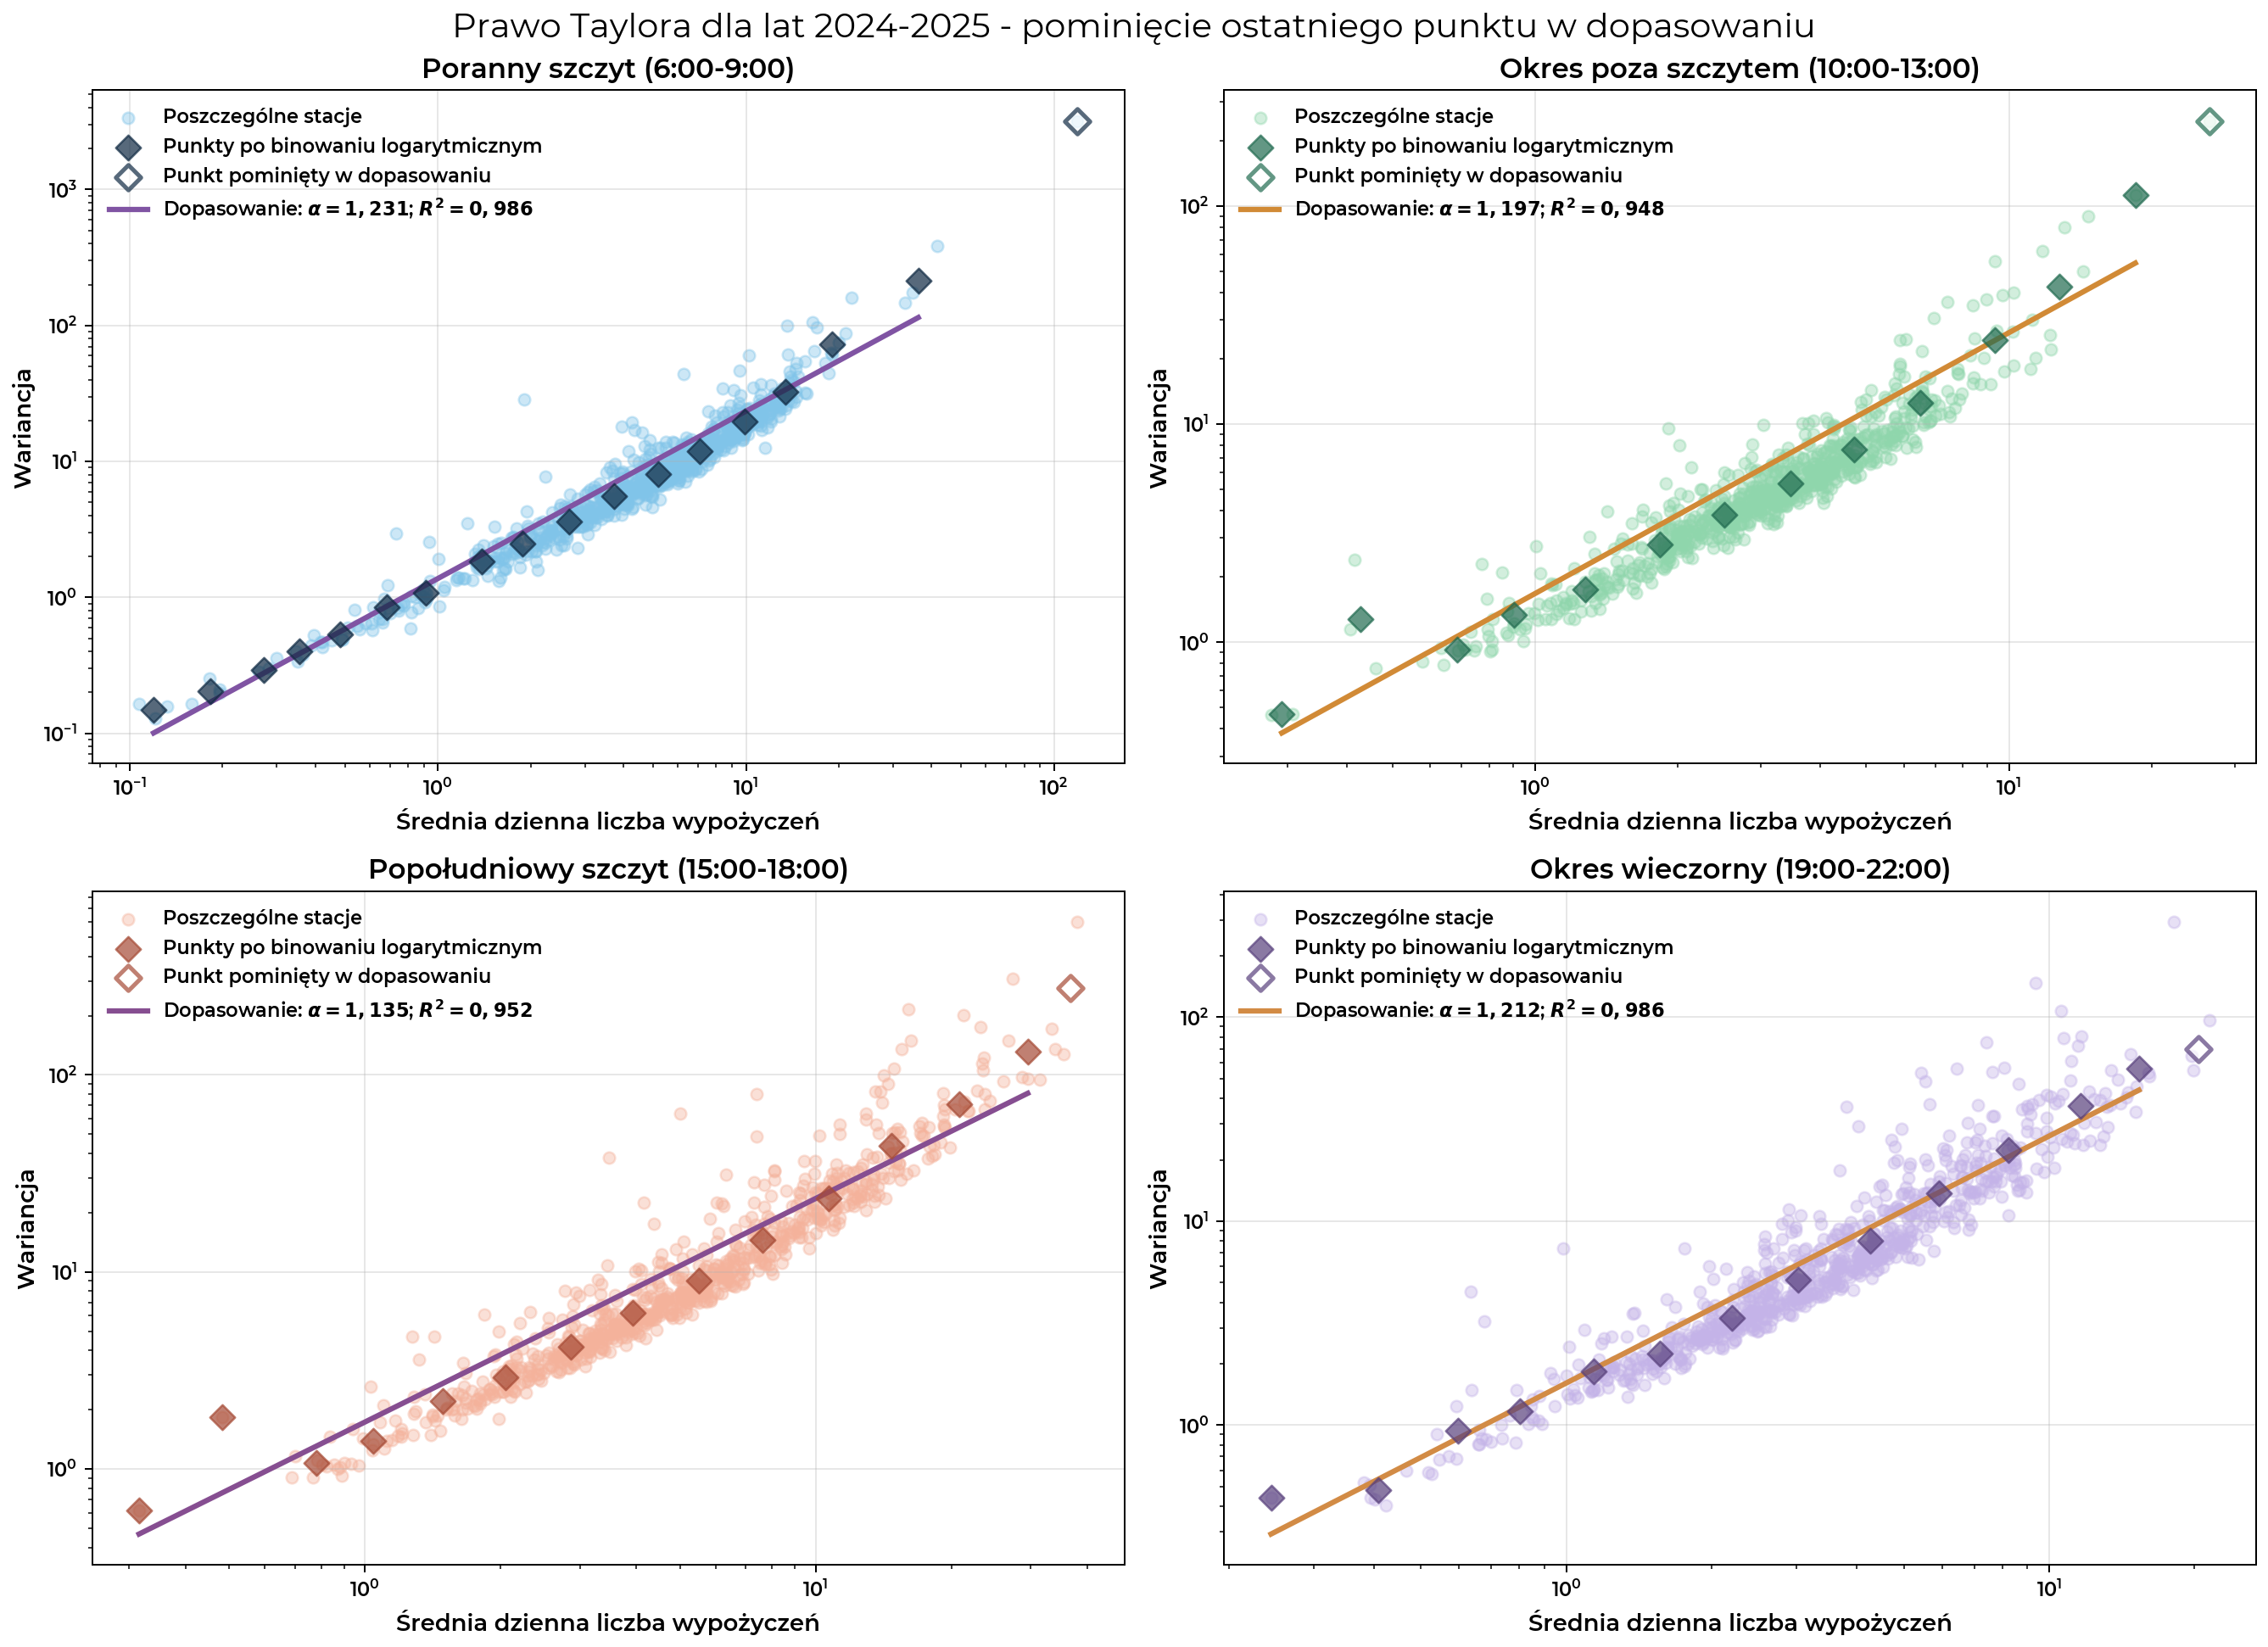

In [12]:
# Logarytmiczne przedziały
morning_peak_mean_log, morning_peak_variance_log = log_binning_aw(
    morning_peak_filtered["mean_count"],
    morning_peak_filtered["variance"],
    a=1.4
)

midday_mean_log, midday_variance_log = log_binning_aw(
    midday_filtered["mean_count"],
    midday_filtered["variance"],
    a=1.4
)

afternoon_peak_mean_log, afternoon_peak_variance_log = log_binning_aw(
    afternoon_peak_filtered["mean_count"],
    afternoon_peak_filtered["variance"],
    a=1.4
)

evening_mean_log, evening_variance_log = log_binning_aw(
    evening_filtered["mean_count"],
    evening_filtered["variance"],
    a=1.4
)

# Dane do wykresów
datasets = {
    "Poranny szczyt (6:00-9:00)": (
        morning_peak_filtered,
        np.asarray(morning_peak_mean_log),
        np.asarray(morning_peak_variance_log)
    ),
    "Okres poza szczytem (10:00-13:00)": (
        midday_filtered,
        np.asarray(midday_mean_log),
        np.asarray(midday_variance_log)
    ),
    "Popołudniowy szczyt (15:00-18:00)": (
        afternoon_peak_filtered,
        np.asarray(afternoon_peak_mean_log),
        np.asarray(afternoon_peak_variance_log)
    ),
    "Okres wieczorny (19:00-22:00)": (
        evening_filtered,
        np.asarray(evening_mean_log),
        np.asarray(evening_variance_log)
    )
}

# Wykres
_apply_project_plot_style()
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

# Kolorystyki dla kolejnych okresów dnia
style_keys = ["morning", "midday", "afternoon_peak", "evening"]

# Opcjonalnie: zapiszmy wyniki dopasowania
fit_results = []

for ax, (period, (data, mean_log, variance_log)), style_key in zip(
    axes, datasets.items(), style_keys
):
    styles = POINT_STYLES[style_key]

    # Dopasowanie prawa Taylora z pominięciem ostatniego punktu
    x = np.log(mean_log[:-1])
    y = np.log(variance_log[:-1])

    alpha, log_A = np.polyfit(x, y, 1)
    A = np.exp(log_A)

    # Ocena jakości dopasowania
    y_pred = alpha * x + log_A

    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)

    r_squared = 1 - ss_res / ss_tot

    r_squared_str = f"{r_squared:.3f}".replace(".", ",")

    # Generowanie punktów dopasowanej funkcji
    x_fit = np.geomspace(min(mean_log[:-1]), max(mean_log[:-1]), 100)
    y_fit = A * x_fit**alpha

    alpha_str = f"{alpha:.3f}".replace(".", ",")

    # Chmura punktów – poszczególne stacje
    ax.scatter(
        data["mean_count"],
        data["variance"],
        color=styles["stations"]["color"],
        alpha=styles["stations"]["alpha"],
        s=styles["stations"]["size"],
        zorder=1,
        label="Poszczególne stacje"
    )

    # Punkty po binowaniu uwzględnione w dopasowaniu
    ax.scatter(
        mean_log[:-1],
        variance_log[:-1],
        color=styles["binned"]["color"],
        alpha=styles["binned"]["alpha"],
        marker=styles["binned"]["marker"],
        s=styles["binned"]["size"],
        zorder=3,
        label="Punkty po binowaniu logarytmicznym"
    )

    # Ostatni punkt pominięty w dopasowaniu
    ax.scatter(
        mean_log[-1],
        variance_log[-1],
        marker=styles["excluded"]["marker"],
        facecolors=styles["excluded"]["facecolor"],
        edgecolors=styles["excluded"]["edgecolor"],
        alpha=styles["excluded"]["alpha"],
        linewidths=styles["excluded"]["linewidth"],
        s=styles["excluded"]["size"],
        zorder=3,
        label="Punkt pominięty w dopasowaniu"
    )

    # Dopasowana funkcja potęgowa
    ax.plot(
        x_fit,
        y_fit,
        color=styles["fit"],
        linewidth=2.5,
        zorder=2,
        label=fr"Dopasowanie: $\alpha = {alpha_str}$; $R^2 = {r_squared_str}$"
    )

    # Skala logarytmiczna
    ax.set_xscale("log")
    ax.set_yscale("log")

    # Opisy wykresu
    ax.set_xlabel("Średnia dzienna liczba wypożyczeń")
    ax.set_ylabel("Wariancja")
    ax.set_title(period)

    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

    # Zapis wyników
    fit_results.append({
        "period": period,
        "alpha": alpha,
        "A": A
    })

fig.suptitle(
    "Prawo Taylora dla lat 2024-2025 - pominięcie ostatniego punktu w dopasowaniu",
    fontsize=16
)

plt.tight_layout()
plt.show()